# Modelos No Supervisados - Métodos de Clustering


# Caso -> **"Clustering de distritos"**

## wd

In [36]:
### Mounting Google Drive :
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [37]:
!pwd

/content/drive/My Drive/raw_data


In [38]:
working_dir = "/content/drive/MyDrive/raw_data"
%cd $working_dir

/content/drive/MyDrive/raw_data


In [39]:
!pwd

/content/drive/MyDrive/raw_data


In [40]:
import pandas as pd

# Librerías y datos : "**1848_Distritos CSE PExt_Pobre.sav**"

In [41]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [42]:
!pip install pyreadstat
import pyreadstat

In [43]:
df, meta = pyreadstat.read_sav('1848_Distritos CSE PExt_Pobre.sav')
print(df.shape)
df.head(5)

(1847, 13)


,COD_UBIG,DEPARTAMENTO,PROVINCIA,DISTRITOS,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,SINEQUIPOSDECOMUNICACION
0,010101,AMAZONAS,CHACHAPOYAS,CHACHAPOYAS,16.546567,21.074099,7.586676,18.150296,1.727577,8.912231,9.957348,3.0,11.504815
1,010102,AMAZONAS,CHACHAPOYAS,ASUNCION,2.000000,22.000000,15.000000,4.580153,44.656489,18.400000,25.190840,2.0,14.843750
2,010103,AMAZONAS,CHACHAPOYAS,BALSAS,54.654655,69.669670,27.627628,18.221831,68.838028,17.823640,9.066901,3.0,14.313380
3,010104,AMAZONAS,CHACHAPOYAS,CHETO,12.735849,16.981132,12.264151,11.059190,30.062305,9.967320,18.224299,3.0,13.948864
4,010105,AMAZONAS,CHACHAPOYAS,CHILIQUIN,78.431373,85.294118,34.313725,5.299145,67.863248,18.671454,7.350427,3.0,15.200243


In [44]:
df.columns

Index(['COD_UBIG', 'DEPARTAMENTO', 'PROVINCIA', 'DISTRITOS', 'NOTIENEAGUA',
       'NOTIENEDESAGUE', 'NOTIENEELECTRICIDAD', 'NOTIENESEGURO', 'RURAL',
       'ANALFABETISMO', 'CONDISCAPACIDAD', 'PROMEDIODEHOGARES',
       'SINEQUIPOSDECOMUNICACION'],
      dtype='object')

Variables:
- **COD_UBIG**:  Código de UBIGEO
- **DEPARTAMENTO**:  Nombre del departamento
- **PROVINCIA**:  Nombre de la provincia
- **DISTRITOS**:  Nombre del distrito
- **NOTIENEAGUA**:  Porcentaje de la población que no tiene agua
- **NOTIENEDESAGUE**:  Porcentaje de la población que no tiene desague
- **NOTIENEELECTRICIDAD**:  Porcentaje de la población que no tiene electricidad
- **NOTIENESEGURO**:  Porcentaje de la población que no tiene seguro de salud
- **RURAL**:  Porcentaje de la población que vive en zona rural
- **ANALFABETISMO**:  Porcentaje de la población que no sabe leer y/o escribir
- **CONDISCAPACIDAD**:  Porcentaje de la población con habilidades especiales
- **PROMEDIODEHOGARES**:  Promedio de hogares por vivienda
- **SINEQUIPOSDECOMUNICACION**:  Porcentaje de la población sin equipos de comunicación

# Preprocesamiento de datos

Tipo de variables

In [45]:
df.dtypes

,0
COD_UBIG,object
DEPARTAMENTO,object
PROVINCIA,object
DISTRITOS,object
NOTIENEAGUA,float64
NOTIENEDESAGUE,float64
NOTIENEELECTRICIDAD,float64
NOTIENESEGURO,float64
RURAL,float64
ANALFABETISMO,float64


Renombramos las filas

In [46]:
df.index = 's' + df['COD_UBIG'].astype('string') + '_' + df['DISTRITOS']
df.head(5)

,COD_UBIG,DEPARTAMENTO,PROVINCIA,DISTRITOS,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,SINEQUIPOSDECOMUNICACION
s010101_CHACHAPOYAS,010101,AMAZONAS,CHACHAPOYAS,CHACHAPOYAS,16.546567,21.074099,7.586676,18.150296,1.727577,8.912231,9.957348,3.0,11.504815
s010102_ASUNCION,010102,AMAZONAS,CHACHAPOYAS,ASUNCION,2.000000,22.000000,15.000000,4.580153,44.656489,18.400000,25.190840,2.0,14.843750
s010103_BALSAS,010103,AMAZONAS,CHACHAPOYAS,BALSAS,54.654655,69.669670,27.627628,18.221831,68.838028,17.823640,9.066901,3.0,14.313380
s010104_CHETO,010104,AMAZONAS,CHACHAPOYAS,CHETO,12.735849,16.981132,12.264151,11.059190,30.062305,9.967320,18.224299,3.0,13.948864
s010105_CHILIQUIN,010105,AMAZONAS,CHACHAPOYAS,CHILIQUIN,78.431373,85.294118,34.313725,5.299145,67.863248,18.671454,7.350427,3.0,15.200243


In [47]:
df[ df.index.duplicated() ]

,COD_UBIG,DEPARTAMENTO,PROVINCIA,DISTRITOS,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,SINEQUIPOSDECOMUNICACION


In [48]:
df.describe()

,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,SINEQUIPOSDECOMUNICACION
count,1847.000000,1847.000000,1847.000000,1847.000000,1847.000000,1847.000000,1847.000000,1847.000000,1847.000000
mean,46.255531,65.890567,22.997177,17.198524,45.423717,16.214400,11.309497,2.814293,13.736639
std,27.170337,25.375554,16.191493,10.462599,30.184871,6.176898,4.784123,0.689773,2.151353
min,0.645161,5.680586,0.000000,1.063830,0.000000,1.770492,1.640958,1.000000,1.473746
25%,22.517996,46.332530,11.625742,8.590437,16.123581,11.391897,8.176472,2.000000,13.072047
50%,41.299304,69.908467,19.408284,15.348924,47.685185,15.739885,10.414290,3.000000,14.184132
75%,68.337354,88.150287,30.180660,24.187175,72.174539,20.562281,13.390849,3.000000,14.928124
max,100.000000,100.000000,100.000000,66.555688,97.798239,40.579022,51.960784,6.000000,18.502964


Esta vez, no se está profundizando en el tratamiento de valores atípicos.

* Tarea: Analizar otros escenarios y evaluar técnicas de tratamiento de valores atípicos.

Tratamiento de valores atípicos

In [49]:
# ...

Tratamiento de valores vacíos

In [50]:
nas = pd.DataFrame(df.isnull().sum()).sort_values(0,ascending=False)
nas.columns = ['nas']
nas['nas%'] = round(nas['nas']/df.shape[0], 2)
nas

,nas,nas%
COD_UBIG,0,0.0
DEPARTAMENTO,0,0.0
PROVINCIA,0,0.0
DISTRITOS,0,0.0
NOTIENEAGUA,0,0.0
NOTIENEDESAGUE,0,0.0
NOTIENEELECTRICIDAD,0,0.0
NOTIENESEGURO,0,0.0
RURAL,0,0.0
ANALFABETISMO,0,0.0


Identificación de variables: Dependiente e Independientes

In [51]:
# Variable Dependiente

# No tenemos

In [52]:
# Variables Independientes
x = df.drop(['COD_UBIG', 'DEPARTAMENTO', 'PROVINCIA', 'DISTRITOS'], axis=1)
print(x.shape)
x.head(5)

(1847, 9)


,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,SINEQUIPOSDECOMUNICACION
s010101_CHACHAPOYAS,16.546567,21.074099,7.586676,18.150296,1.727577,8.912231,9.957348,3.0,11.504815
s010102_ASUNCION,2.000000,22.000000,15.000000,4.580153,44.656489,18.400000,25.190840,2.0,14.843750
s010103_BALSAS,54.654655,69.669670,27.627628,18.221831,68.838028,17.823640,9.066901,3.0,14.313380
s010104_CHETO,12.735849,16.981132,12.264151,11.059190,30.062305,9.967320,18.224299,3.0,13.948864
s010105_CHILIQUIN,78.431373,85.294118,34.313725,5.299145,67.863248,18.671454,7.350427,3.0,15.200243


Tipo de variables

In [53]:
x.dtypes

,0
NOTIENEAGUA,float64
NOTIENEDESAGUE,float64
NOTIENEELECTRICIDAD,float64
NOTIENESEGURO,float64
RURAL,float64
ANALFABETISMO,float64
CONDISCAPACIDAD,float64
PROMEDIODEHOGARES,float64
SINEQUIPOSDECOMUNICACION,float64


# Transformación de datos

In [54]:
print(x.shape)
x.head()

(1847, 9)


,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,SINEQUIPOSDECOMUNICACION
s010101_CHACHAPOYAS,16.546567,21.074099,7.586676,18.150296,1.727577,8.912231,9.957348,3.0,11.504815
s010102_ASUNCION,2.000000,22.000000,15.000000,4.580153,44.656489,18.400000,25.190840,2.0,14.843750
s010103_BALSAS,54.654655,69.669670,27.627628,18.221831,68.838028,17.823640,9.066901,3.0,14.313380
s010104_CHETO,12.735849,16.981132,12.264151,11.059190,30.062305,9.967320,18.224299,3.0,13.948864
s010105_CHILIQUIN,78.431373,85.294118,34.313725,5.299145,67.863248,18.671454,7.350427,3.0,15.200243


In [55]:
x.describe()

,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,SINEQUIPOSDECOMUNICACION
count,1847.000000,1847.000000,1847.000000,1847.000000,1847.000000,1847.000000,1847.000000,1847.000000,1847.000000
mean,46.255531,65.890567,22.997177,17.198524,45.423717,16.214400,11.309497,2.814293,13.736639
std,27.170337,25.375554,16.191493,10.462599,30.184871,6.176898,4.784123,0.689773,2.151353
min,0.645161,5.680586,0.000000,1.063830,0.000000,1.770492,1.640958,1.000000,1.473746
25%,22.517996,46.332530,11.625742,8.590437,16.123581,11.391897,8.176472,2.000000,13.072047
50%,41.299304,69.908467,19.408284,15.348924,47.685185,15.739885,10.414290,3.000000,14.184132
75%,68.337354,88.150287,30.180660,24.187175,72.174539,20.562281,13.390849,3.000000,14.928124
max,100.000000,100.000000,100.000000,66.555688,97.798239,40.579022,51.960784,6.000000,18.502964


In [56]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

x_scaled1 = pd.DataFrame(scaler.fit_transform(x), index = x.index )
x_scaled1.columns = x.columns
x_scaled1.head(3)

,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,SINEQUIPOSDECOMUNICACION
s010101_CHACHAPOYAS,0.160047,0.163206,0.075867,0.260895,0.017665,0.184025,0.165271,0.4,0.589050
s010102_ASUNCION,0.013636,0.173023,0.150000,0.053691,0.456619,0.428501,0.468004,0.2,0.785121
s010103_BALSAS,0.543602,0.678430,0.276276,0.261987,0.703878,0.413650,0.147575,0.4,0.753977


In [57]:
#import pickle
#pickle.dump(scaler, open('scaler.pkl','wb'))
##loaded_scaler = pickle.load(open('scaler.pkl','rb'))

In [58]:
x.head(3)

,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,SINEQUIPOSDECOMUNICACION
s010101_CHACHAPOYAS,16.546567,21.074099,7.586676,18.150296,1.727577,8.912231,9.957348,3.0,11.504815
s010102_ASUNCION,2.000000,22.000000,15.000000,4.580153,44.656489,18.400000,25.190840,2.0,14.843750
s010103_BALSAS,54.654655,69.669670,27.627628,18.221831,68.838028,17.823640,9.066901,3.0,14.313380


In [59]:
x_scaled2 = x.copy()
x_scaled2.head(3)

,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,SINEQUIPOSDECOMUNICACION
s010101_CHACHAPOYAS,16.546567,21.074099,7.586676,18.150296,1.727577,8.912231,9.957348,3.0,11.504815
s010102_ASUNCION,2.000000,22.000000,15.000000,4.580153,44.656489,18.400000,25.190840,2.0,14.843750
s010103_BALSAS,54.654655,69.669670,27.627628,18.221831,68.838028,17.823640,9.066901,3.0,14.313380


In [60]:
x_scaled2[['NOTIENEAGUA', 'NOTIENEDESAGUE', 'NOTIENEELECTRICIDAD', 'NOTIENESEGURO', 'RURAL',
           'ANALFABETISMO', 'CONDISCAPACIDAD', 'SINEQUIPOSDECOMUNICACION']] = x_scaled2[['NOTIENEAGUA', 'NOTIENEDESAGUE', 'NOTIENEELECTRICIDAD', 'NOTIENESEGURO', 'RURAL',
           'ANALFABETISMO', 'CONDISCAPACIDAD', 'SINEQUIPOSDECOMUNICACION']] / 100
x_scaled2.head(3)

,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,SINEQUIPOSDECOMUNICACION
s010101_CHACHAPOYAS,0.165466,0.210741,0.075867,0.181503,0.017276,0.089122,0.099573,3.0,0.115048
s010102_ASUNCION,0.020000,0.220000,0.150000,0.045802,0.446565,0.184000,0.251908,2.0,0.148438
s010103_BALSAS,0.546547,0.696697,0.276276,0.182218,0.688380,0.178236,0.090669,3.0,0.143134


In [61]:
scaler = MinMaxScaler()

x_scaled2['PROMEDIODEHOGARES'] = pd.DataFrame(scaler.fit_transform(np.array(x_scaled2['PROMEDIODEHOGARES']).reshape(-1,1)), index = x.index )
x_scaled2.head(3)

,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,SINEQUIPOSDECOMUNICACION
s010101_CHACHAPOYAS,0.165466,0.210741,0.075867,0.181503,0.017276,0.089122,0.099573,0.4,0.115048
s010102_ASUNCION,0.020000,0.220000,0.150000,0.045802,0.446565,0.184000,0.251908,0.2,0.148438
s010103_BALSAS,0.546547,0.696697,0.276276,0.182218,0.688380,0.178236,0.090669,0.4,0.143134


In [62]:
x_scaled2.describe()

,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,SINEQUIPOSDECOMUNICACION
count,1847.000000,1847.000000,1847.000000,1847.000000,1847.000000,1847.000000,1847.000000,1847.000000,1847.000000
mean,0.462555,0.658906,0.229972,0.171985,0.454237,0.162144,0.113095,0.362859,0.137366
std,0.271703,0.253756,0.161915,0.104626,0.301849,0.061769,0.047841,0.137955,0.021514
min,0.006452,0.056806,0.000000,0.010638,0.000000,0.017705,0.016410,0.000000,0.014737
25%,0.225180,0.463325,0.116257,0.085904,0.161236,0.113919,0.081765,0.200000,0.130720
50%,0.412993,0.699085,0.194083,0.153489,0.476852,0.157399,0.104143,0.400000,0.141841
75%,0.683374,0.881503,0.301807,0.241872,0.721745,0.205623,0.133908,0.400000,0.149281
max,1.000000,1.000000,1.000000,0.665557,0.977982,0.405790,0.519608,1.000000,0.185030


# **Modelo 1: "K-Means"**

In [63]:
from sklearn.cluster import KMeans

modelo1 = KMeans(random_state = 2022)

Grid para búsqueda de parámetros óptimos

In [64]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from tqdm.auto import tqdm

param_grid = {
    'n_clusters': [2, 3, 4],    # Cantidad de Clusters
    'max_iter': [100, 200],     # Cantidad máxima de iteraciones
    'n_init': [10, 25]          # Cantidad de observaciones para iniciación
}


In [66]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from tqdm.auto import tqdm
import pandas as pd

param_grid = {
    'n_clusters': [2, 3, 4, 5, 6, 7, 8, 9, 10],
    'max_iter': [100, 200, 300],
    'n_init': [10, 25, 50]
}

resultados_kmeans_grid = []

total = (
    len(param_grid['n_clusters'])
    * len(param_grid['max_iter'])
    * len(param_grid['n_init'])
)

with tqdm(
    total=total,
    desc="K-Means",
    unit="modelo"
) as pbar:

    for n_clusters in param_grid['n_clusters']:
        for max_iter in param_grid['max_iter']:
            for n_init in param_grid['n_init']:

                pbar.set_postfix(
                    n_clusters=n_clusters,
                    max_iter=max_iter,
                    n_init=n_init
                )

                modelo = KMeans(
                    n_clusters=n_clusters,
                    max_iter=max_iter,
                    n_init=n_init,
                    random_state=2022
                )

                clusters = modelo.fit_predict(
                    x_scaled2.select_dtypes(include="float64")
                )

                silhouette = silhouette_score(
                    D,
                    clusters,
                    metric='precomputed'
                )

                resultados_kmeans_grid.append({
                    'n_clusters': n_clusters,
                    'max_iter': max_iter,
                    'n_init': n_init,
                    'inertia': modelo.inertia_,
                    'silhouette_gower': silhouette
                })

                pbar.update(1)

resultados_kmeans_grid = pd.DataFrame(
    resultados_kmeans_grid
)


K-Means:   0%|          | 0/81 [00:00<?, ?modelo/s]

ValueError: Expected 2D array, got 1D array instead:
array=[0.55024386 0.93847256 0.3133245  ... 0.33280884 0.71799415 0.93323271].
Reshape your data either using array.reshape(-1, 1) if your data has a single feature or array.reshape(1, -1) if it contains a single sample.

In [ ]:
mejor_modelo = resultados_kmeans_grid.sort_values(
    'silhouette_gower',
    ascending=False
)

mejor_modelo


## **Gráfico del Codo** : Selección del "K" óptimo

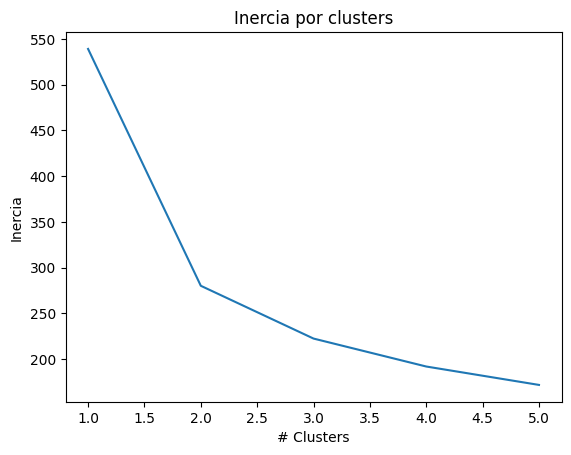

In [69]:
inertias = []

for i in range(1, 6):
    kmeans = KMeans(n_clusters = i, max_iter=100, n_init=10, random_state=2022)
    kmeans.fit(x_scaled2)
    inertias.append(kmeans.inertia_)

plt.plot(range(1, 6), inertias)
plt.title('Inercia por clusters')
plt.xlabel('# Clusters')
plt.ylabel('Inercia')
plt.show()

In [70]:
kmeans_per_k = [KMeans(n_clusters = k, max_iter=100, n_init=10, random_state=2022).fit(x_scaled2)
                for k in range(1, 10)]
inertias = [model.inertia_ for model in kmeans_per_k]
inertias

[539.195887878087,
 279.99443059120676,
 222.2356923618033,
 191.64656209069614,
 171.50489917730522,
 158.71928239205133,
 147.42404267368735,
 139.784370034073,
 133.07891630837062]

In [71]:
list(range(1, 10))

[1, 2, 3, 4, 5, 6, 7, 8, 9]

La métrica que determina la bondad de un modelo se llama inercia. Se calcula como la distancia cuadrática media entre cada instancia y el centroide más cercano.

El algoritmo k-means se ejecuta n_init veces y se escoge el modelo con el menor valor de inercia. Usualmente el score de un modelo sigue la regla “mayor es mejor”, por este motivo se maneja un valor negativo de inercia.

## **Gráfico de Silueta** : Selección del "K" óptimo

In [72]:
from sklearn.metrics import silhouette_score
silhouette_scores = [silhouette_score(x_scaled2, model.labels_)
                     for model in kmeans_per_k[1:]]


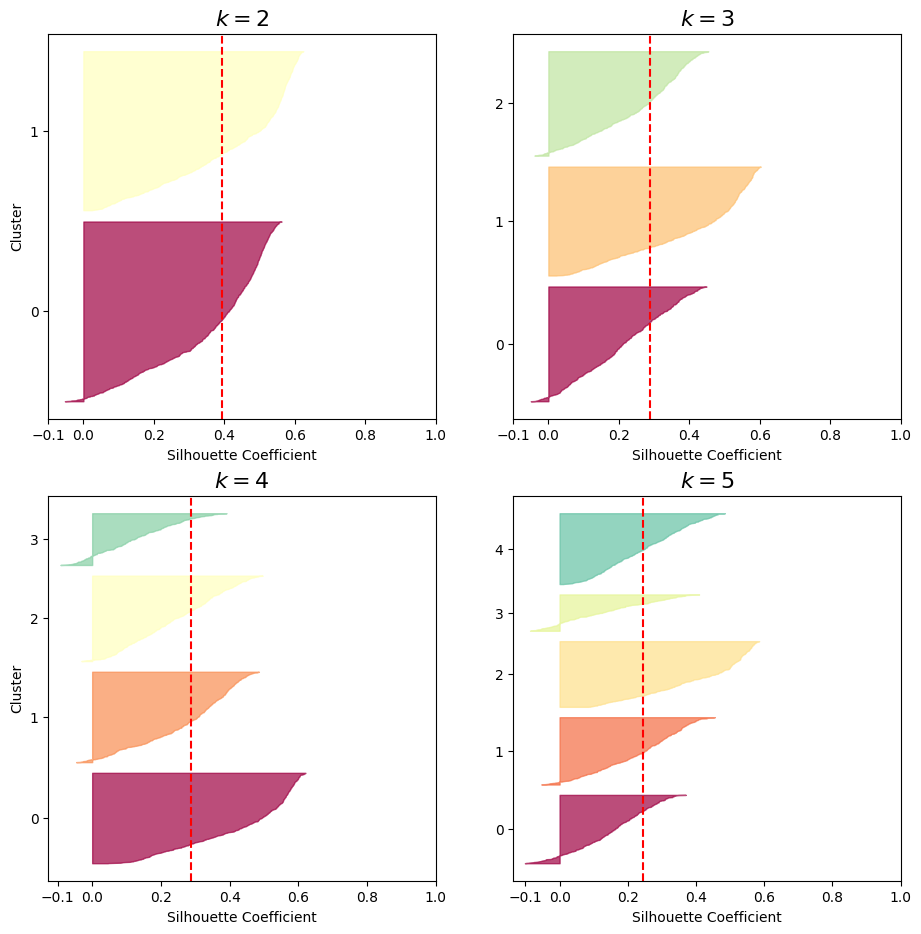

In [73]:
from sklearn.metrics import silhouette_samples
from matplotlib.ticker import FixedLocator, FixedFormatter

plt.figure(figsize=(11, 11))

for k in (2, 3, 4, 5):
    plt.subplot(2, 2, k - 1)

    y_pred = kmeans_per_k[k - 1].labels_
    silhouette_coefficients = silhouette_samples(x_scaled2, y_pred)

    padding = len(x_scaled2) // 30
    pos = padding
    ticks = []
    for i in range(k):
        coeffs = silhouette_coefficients[y_pred == i]
        coeffs.sort()

        color = plt.cm.Spectral(i / k)
        plt.fill_betweenx(np.arange(pos, pos + len(coeffs)), 0, coeffs,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos + len(coeffs) // 2)
        pos += len(coeffs) + padding

    plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
    plt.gca().yaxis.set_major_formatter(FixedFormatter(range(k)))
    if k in (2, 4):
        plt.ylabel("Cluster")

    if k in (2, 3, 4, 5):
        plt.gca().set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
        plt.xlabel("Silhouette Coefficient")
    else:
        plt.tick_params(labelbottom=False)

    plt.axvline(x=silhouette_scores[k - 2], color="red", linestyle="--")
    plt.title("$k={}$".format(k), fontsize=16)

plt.show()

- Tamaños de silueta por cluster más homogéneos entre sí
- No presencia de muchos valores hacia -1
- Score de silueta promedio mayor respecto a otros k

## **Modelo 1: K-Means** (con K óptimo)

In [74]:
modelo1 = KMeans(n_clusters = 3, max_iter=100, n_init=10, random_state=2022)

In [75]:
x['Cluster_modelo1'] = modelo1.fit_predict(x_scaled2)
print(x.columns)
x.head(5)

Index(['NOTIENEAGUA', 'NOTIENEDESAGUE', 'NOTIENEELECTRICIDAD', 'NOTIENESEGURO',
       'RURAL', 'ANALFABETISMO', 'CONDISCAPACIDAD', 'PROMEDIODEHOGARES',
       'SINEQUIPOSDECOMUNICACION', 'Cluster_modelo1'],
      dtype='object')


,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,SINEQUIPOSDECOMUNICACION,Cluster_modelo1
s010101_CHACHAPOYAS,16.546567,21.074099,7.586676,18.150296,1.727577,8.912231,9.957348,3.0,11.504815,1
s010102_ASUNCION,2.000000,22.000000,15.000000,4.580153,44.656489,18.400000,25.190840,2.0,14.843750,1
s010103_BALSAS,54.654655,69.669670,27.627628,18.221831,68.838028,17.823640,9.066901,3.0,14.313380,0
s010104_CHETO,12.735849,16.981132,12.264151,11.059190,30.062305,9.967320,18.224299,3.0,13.948864,1
s010105_CHILIQUIN,78.431373,85.294118,34.313725,5.299145,67.863248,18.671454,7.350427,3.0,15.200243,2


In [76]:
x['Cluster_modelo1']

,Cluster_modelo1
s010101_CHACHAPOYAS,1
s010102_ASUNCION,1
s010103_BALSAS,0
s010104_CHETO,1
s010105_CHILIQUIN,2
...,...
s250302_IRAZOLA,0
s250303_CURIMANA,2
s250304_NESHUYA,0
s250305_ALEXANDER VON HUMBOLDT,1


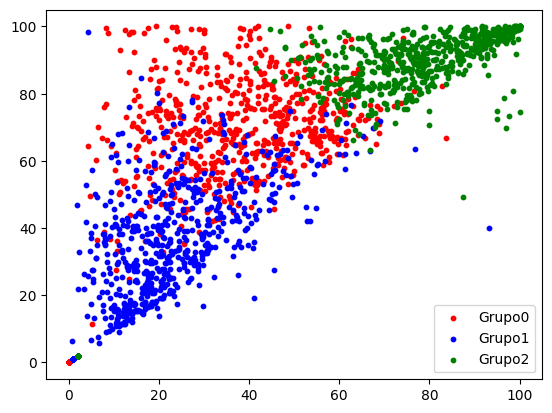

In [77]:
plt.scatter(x[x.Cluster_modelo1 == 0][['Cluster_modelo1', 'NOTIENEAGUA']], x[x.Cluster_modelo1 == 0][['Cluster_modelo1', 'NOTIENEDESAGUE']], s = 10, c = 'red', label = 'Grupo0')
plt.scatter(x[x.Cluster_modelo1 == 1][['Cluster_modelo1', 'NOTIENEAGUA']], x[x.Cluster_modelo1 == 1][['Cluster_modelo1', 'NOTIENEDESAGUE']], s = 10, c = 'blue', label = 'Grupo1')
plt.scatter(x[x.Cluster_modelo1 == 2][['Cluster_modelo1', 'NOTIENEAGUA']], x[x.Cluster_modelo1 == 2][['Cluster_modelo1', 'NOTIENEDESAGUE']], s = 10, c = 'green', label = 'Grupo2')
plt.legend()

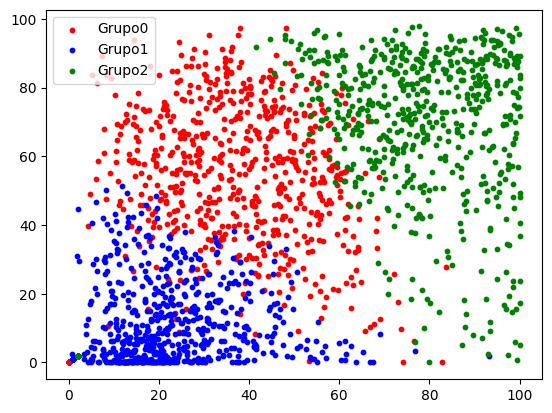

In [78]:
plt.scatter(x[x.Cluster_modelo1 == 0][['Cluster_modelo1', 'NOTIENEAGUA']], x[x.Cluster_modelo1 == 0][['Cluster_modelo1', 'RURAL']], s = 10, c = 'red', label = 'Grupo0')
plt.scatter(x[x.Cluster_modelo1 == 1][['Cluster_modelo1', 'NOTIENEAGUA']], x[x.Cluster_modelo1 == 1][['Cluster_modelo1', 'RURAL']], s = 10, c = 'blue', label = 'Grupo1')
plt.scatter(x[x.Cluster_modelo1 == 2][['Cluster_modelo1', 'NOTIENEAGUA']], x[x.Cluster_modelo1 == 2][['Cluster_modelo1', 'RURAL']], s = 10, c = 'green', label = 'Grupo2')
plt.legend()

In [79]:
# Descriptivos Cluster rojo
x[x.Cluster_modelo1 == 0].describe()

,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,SINEQUIPOSDECOMUNICACION,Cluster_modelo1
count,646.000000,646.000000,646.000000,646.000000,646.000000,646.000000,646.000000,646.000000,646.000000,646.0
mean,37.910458,70.491184,21.767440,14.819764,55.166215,17.740610,11.441368,2.739938,14.282581,0.0
std,15.195791,14.367896,10.463936,9.666922,19.533444,5.383936,4.958385,0.591686,0.942316,0.0
min,4.375000,11.340206,1.923077,1.063830,0.000000,1.770492,1.640958,1.000000,8.098548,0.0
25%,26.135128,61.139298,14.336386,7.373032,41.474085,13.898886,7.946561,2.000000,13.724415,0.0
50%,37.873364,69.893992,20.071011,12.261133,55.985097,17.387432,10.279941,3.000000,14.273333,0.0
75%,48.973146,79.928486,27.679502,20.591843,70.454315,21.138427,13.868099,3.000000,14.794304,0.0
max,83.675464,100.000000,59.618008,58.083702,97.308828,37.574850,34.221311,5.000000,18.413866,0.0


In [80]:
# Descriptivos Cluster verde
x[x.Cluster_modelo1 == 2].describe()

,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,SINEQUIPOSDECOMUNICACION,Cluster_modelo1
count,588.000000,588.000000,588.000000,588.000000,588.000000,588.000000,588.000000,588.000000,588.000000,588.0
mean,79.129015,90.296415,36.011505,14.599726,69.544252,19.452713,10.729190,2.761054,15.069295,2.0
std,13.676474,7.625517,18.435191,10.408328,21.084130,5.613238,5.291333,0.803716,1.077562,0.0
min,41.500000,49.201278,5.228758,1.616304,0.176389,5.411499,1.688404,1.000000,10.423211,2.0
25%,69.320158,85.450638,22.512417,6.767499,58.775125,15.624377,6.900906,2.000000,14.406751,2.0
50%,78.840028,91.723889,32.257146,11.087466,74.079881,19.397633,9.752395,3.000000,14.915463,2.0
75%,91.490923,96.597356,44.736239,20.667768,86.100182,23.350004,13.451862,3.000000,15.719103,2.0
max,100.000000,100.000000,100.000000,66.555688,97.798239,40.579022,51.960784,6.000000,18.502964,2.0


In [81]:
# Descriptivos Cluster azul
x[x.Cluster_modelo1 == 1].describe()

,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,SINEQUIPOSDECOMUNICACION,Cluster_modelo1
count,613.000000,613.000000,613.000000,613.000000,613.000000,613.000000,613.000000,613.000000,613.000000,613.0
mean,23.517044,37.631781,11.809550,22.198151,12.019920,11.499784,11.727169,2.943719,11.883001,1.0
std,13.202124,16.566371,7.727315,9.502184,11.955984,4.417742,3.969267,0.649042,2.539393,0.0
min,0.645161,5.680586,0.000000,1.923077,0.000000,3.317119,4.482759,1.000000,1.473746,1.0
25%,13.901345,24.686731,6.315726,15.286236,2.004812,8.586976,9.377497,3.000000,10.709034,1.0
50%,20.833333,36.247086,10.491563,21.906181,8.184348,10.625277,10.778603,3.000000,12.376238,1.0
75%,29.832613,49.700599,15.869803,28.878620,19.152965,13.600000,12.885090,3.000000,13.588627,1.0
max,93.157895,98.406375,58.407080,63.675958,51.365507,33.115672,30.578512,4.000000,17.108813,1.0


# **Modelo 3: Jerarquico - Aglomerativo**

In [82]:
from scipy.cluster.hierarchy import linkage, dendrogram

In [83]:
x_scaled2.head(3) # Solo tiene las variables numericas

,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,SINEQUIPOSDECOMUNICACION
s010101_CHACHAPOYAS,0.165466,0.210741,0.075867,0.181503,0.017276,0.089122,0.099573,0.4,0.115048
s010102_ASUNCION,0.020000,0.220000,0.150000,0.045802,0.446565,0.184000,0.251908,0.2,0.148438
s010103_BALSAS,0.546547,0.696697,0.276276,0.182218,0.688380,0.178236,0.090669,0.4,0.143134


In [84]:
from scipy.spatial.distance import pdist, squareform

D = squareform(pdist(x_scaled2, metric='euclidean')) # Matriz de distancias euclidianas; si hay variables mixtas, se encuentra la forma
D

array([[0.        , 0.55024386, 0.93847256, ..., 0.85285863, 0.64413091,
        1.38022013],
       [0.55024386, 0.        , 0.81460445, ..., 0.87333729, 0.81710131,
        1.3839475 ],
       [0.93847256, 0.81460445, 0.        , ..., 0.31715828, 0.57140456,
        0.66362561],
       ...,
       [0.85285863, 0.87333729, 0.31715828, ..., 0.        , 0.33280884,
        0.71799415],
       [0.64413091, 0.81710131, 0.57140456, ..., 0.33280884, 0.        ,
        0.93323271],
       [1.38022013, 1.3839475 , 0.66362561, ..., 0.71799415, 0.93323271,
        0.        ]])

In [85]:
D = pdist(x_scaled2, metric='euclidean')

Z = linkage(D, method='single') # Se quita la redundancia de los valores
Z

array([[1.28200000e+03, 1.30700000e+03, 1.17439715e-02, 2.00000000e+00],
       [1.27600000e+03, 1.27800000e+03, 1.37536939e-02, 2.00000000e+00],
       [1.28600000e+03, 1.30200000e+03, 1.73872336e-02, 2.00000000e+00],
       ...,
       [1.70900000e+03, 3.68900000e+03, 3.80796408e-01, 1.84500000e+03],
       [1.80100000e+03, 3.69000000e+03, 3.83923237e-01, 1.84600000e+03],
       [1.02500000e+03, 3.69100000e+03, 3.84676908e-01, 1.84700000e+03]])

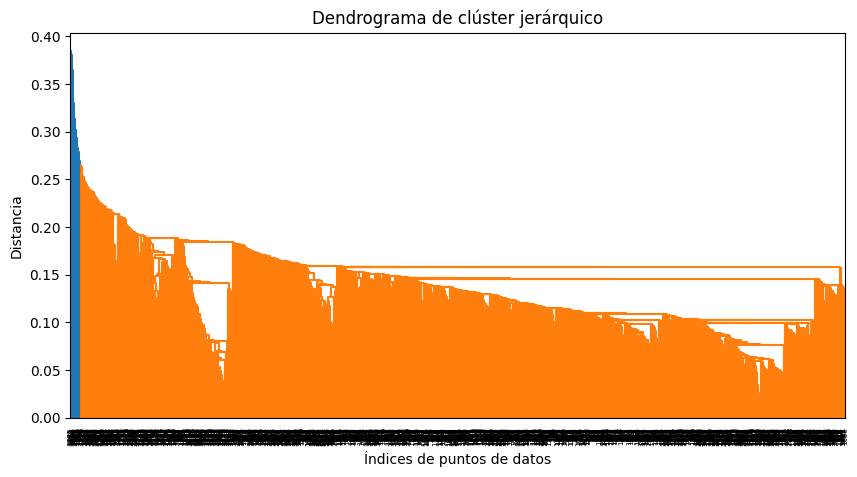

In [86]:
plt.figure(figsize=(10, 5))
dendrogram(Z)
plt.title('Dendrograma de clúster jerárquico')
plt.xlabel('Índices de puntos de datos')
plt.ylabel('Distancia')
plt.show()

Principales opciones:

'single' → usa la distancia mínima entre puntos de dos clústeres. Puede generar el efecto de cadena.

'complete' → usa la distancia máxima entre puntos. Tiende a producir clústeres más compactos.

'average' → usa la distancia promedio entre puntos de los dos clústeres.

'weighted' → parecido a average, pero pondera los clústeres de manera diferente.

'centroid' → calcula la distancia entre los centroides de los clústeres.

'median' → similar a centroid, pero utiliza una actualización basada en los centroides de forma ponderada.

'ward' → busca minimizar el aumento de la varianza interna al unir clústeres. Es muy utilizado, pero tiene una condición importante: normalmente debe usarse con distancias euclídeas sobre datos numéricos, no con una matriz de distancias arbitraria; es solo para dendogramas numericos (no mixtas)

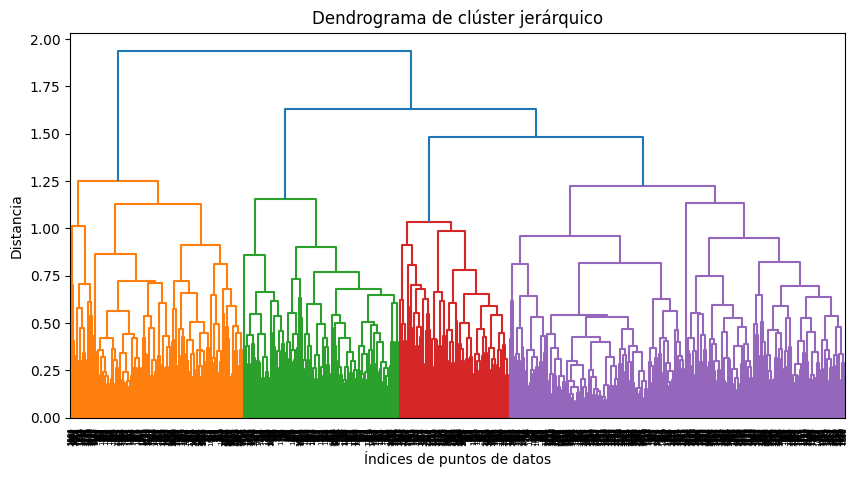

In [87]:
Z = linkage(D, method='complete')

plt.figure(figsize=(10, 5))
dendrogram(Z)
plt.title('Dendrograma de clúster jerárquico')
plt.xlabel('Índices de puntos de datos')
plt.ylabel('Distancia')
plt.show()

In [88]:
Z_single = linkage(D, method='single')
Z_complete = linkage(D, method='complete')
Z_average = linkage(D, method='average')

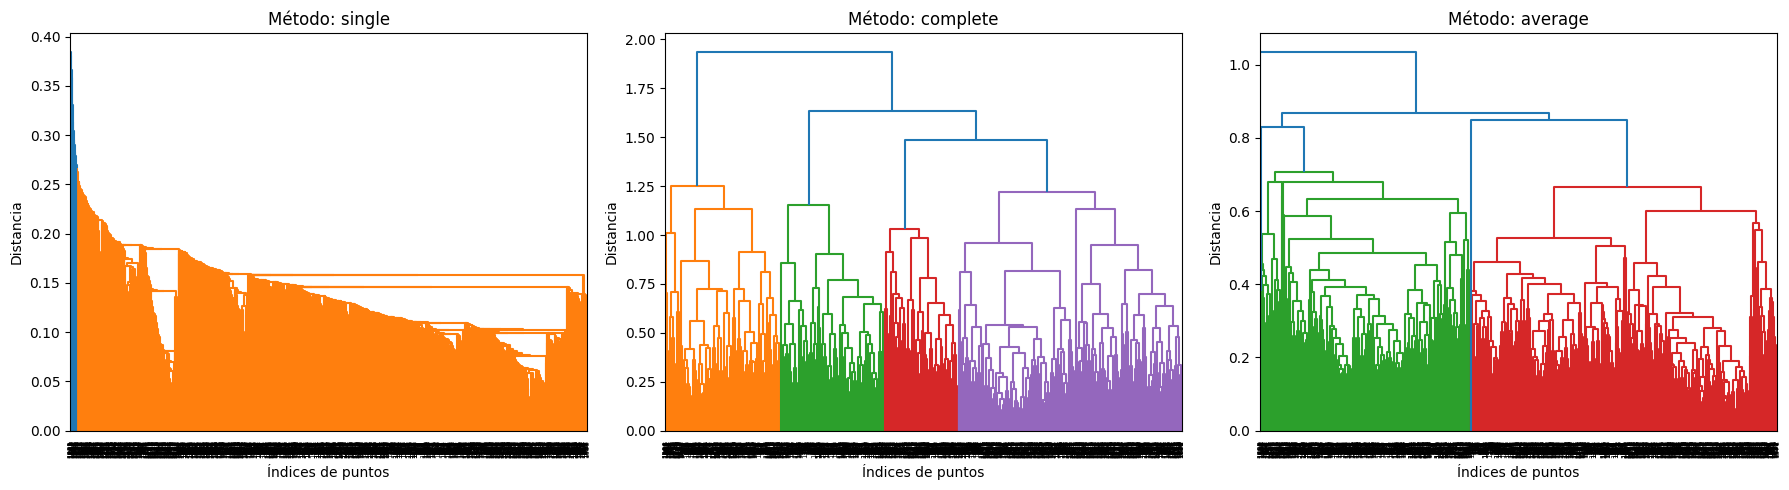

In [89]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, method in zip(
    axes,
    ['single', 'complete', 'average']
):
    Z = linkage(D, method=method)
    dendrogram(Z, ax=ax)
    ax.set_title(f'Método: {method}')
    ax.set_xlabel('Índices de puntos')
    ax.set_ylabel('Distancia')

plt.tight_layout()
plt.show()


In [90]:
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.metrics import silhouette_score

metodos = ['single', 'complete', 'average']

for metodo in metodos:
    Z = linkage(D, method=metodo)
    labels = fcluster(Z, 3, criterion='maxclust')

    score = silhouette_score(
        squareform(D),
        labels,
        metric='precomputed'
    )

    print(metodo, score)


single 0.1722961135153415
complete 0.20619299819574974
average 0.3178508558968398


Buscamos: mayor separación de los grupos según el Silhouette Score

In [91]:
from scipy.cluster.hierarchy import fcluster

Z = linkage(D, method='complete')

x['Cluster_modelo3'] = fcluster(Z, t=3, criterion='maxclust') # Guardo este cluster; es una particion en 3; ¿que pasa si lo partimos en 4? los grupos son diferentes; para cada grupo haremos un descriptivo univariado

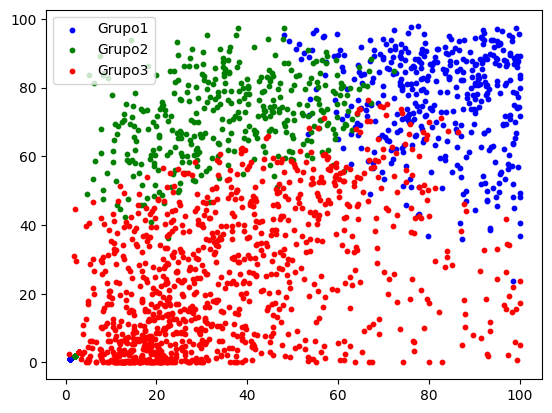

In [92]:
plt.scatter(x[x.Cluster_modelo3 == 1][['Cluster_modelo3', 'NOTIENEAGUA']], x[x.Cluster_modelo3 == 1][['Cluster_modelo3', 'RURAL']], s = 10, c = 'blue', label = 'Grupo1')
plt.scatter(x[x.Cluster_modelo3 == 2][['Cluster_modelo3', 'NOTIENEAGUA']], x[x.Cluster_modelo3 == 2][['Cluster_modelo3', 'RURAL']], s = 10, c = 'green', label = 'Grupo2')
plt.scatter(x[x.Cluster_modelo3 == 3][['Cluster_modelo3', 'NOTIENEAGUA']], x[x.Cluster_modelo3 == 3][['Cluster_modelo3', 'RURAL']], s = 10, c = 'red', label = 'Grupo3')
plt.legend()

# **Modelo 2: K-Prototypes**

In [93]:
!pip install kmodes
!pip install KPrototypes

In [94]:
from kmodes.kprototypes import KPrototypes

modelo2 = KPrototypes(random_state = 2022, init = 'random', n_jobs = -1)

## **Discretizamos "SINEQUIPOSDECOMUNICACION"** : (misma amplitud y diferente frecuencia)

Para que el  K-prototype tenga sentido usarla, debe haber por lo menos una categorica, sino mejor uso el K-means

In [95]:
x_scaled2.head(1)

,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,SINEQUIPOSDECOMUNICACION
s010101_CHACHAPOYAS,0.165466,0.210741,0.075867,0.181503,0.017276,0.089122,0.099573,0.4,0.115048


In [96]:
x_scaled2.SINEQUIPOSDECOMUNICACION.describe()

,SINEQUIPOSDECOMUNICACION
count,1847.000000
mean,0.137366
std,0.021514
min,0.014737
25%,0.130720
50%,0.141841
75%,0.149281
max,0.185030


Vamos a discretizar 'SINEQUIPOSDECOMUNICACION'

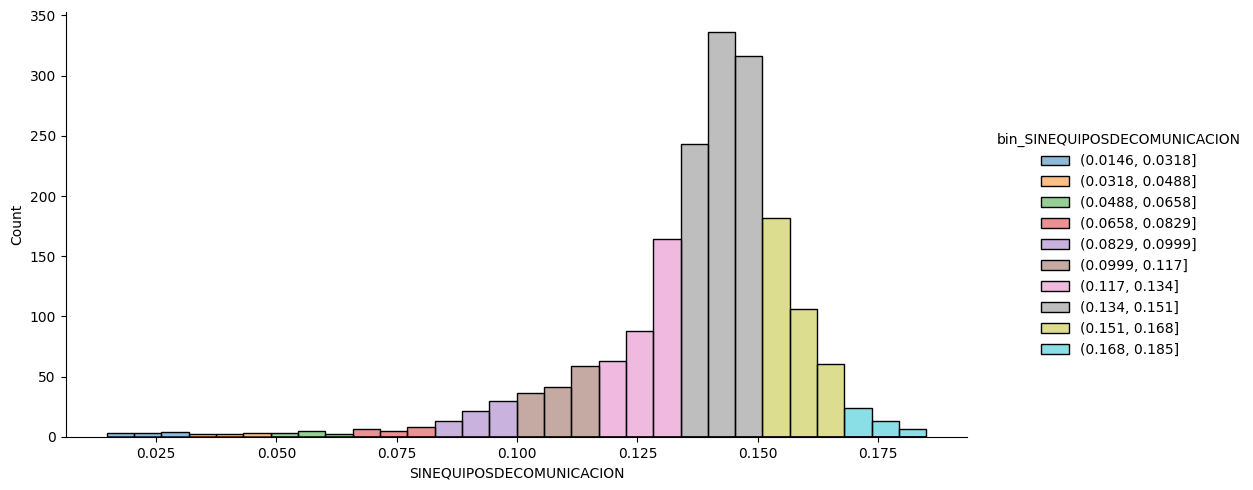

In [97]:
x_scaled2['bin_SINEQUIPOSDECOMUNICACION'] = pd.cut(x_scaled2.SINEQUIPOSDECOMUNICACION, 10) # Cortamos en 10 bloques para que se tenga la misma distancia y diferentes observaciones
sns.displot(x_scaled2, x='SINEQUIPOSDECOMUNICACION', hue='bin_SINEQUIPOSDECOMUNICACION', aspect=2, bins=30)

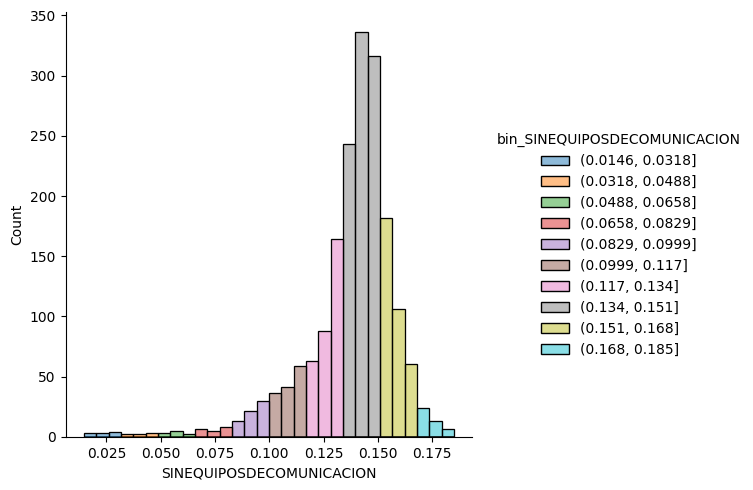

In [98]:
sns.displot(x_scaled2, x='SINEQUIPOSDECOMUNICACION', hue='bin_SINEQUIPOSDECOMUNICACION', aspect=1, bins=30)

In [99]:
x_scaled2.drop('SINEQUIPOSDECOMUNICACION', axis=1, inplace=True) # Excluimos la original

In [100]:
print(x_scaled2.dtypes)
x_scaled2.head(3) # Con esto (posicion de todo mi vector de columnas) construiremos el k-prototype

NOTIENEAGUA                      float64
NOTIENEDESAGUE                   float64
NOTIENEELECTRICIDAD              float64
NOTIENESEGURO                    float64
RURAL                            float64
ANALFABETISMO                    float64
CONDISCAPACIDAD                  float64
PROMEDIODEHOGARES                float64
bin_SINEQUIPOSDECOMUNICACION    category
dtype: object


,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,bin_SINEQUIPOSDECOMUNICACION
s010101_CHACHAPOYAS,0.165466,0.210741,0.075867,0.181503,0.017276,0.089122,0.099573,0.4,"(0.0999, 0.117]"
s010102_ASUNCION,0.020000,0.220000,0.150000,0.045802,0.446565,0.184000,0.251908,0.2,"(0.134, 0.151]"
s010103_BALSAS,0.546547,0.696697,0.276276,0.182218,0.688380,0.178236,0.090669,0.4,"(0.134, 0.151]"


## **Identificamos posición de variables categóricas**

In [101]:
x_scaled2.head(3)

,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,bin_SINEQUIPOSDECOMUNICACION
s010101_CHACHAPOYAS,0.165466,0.210741,0.075867,0.181503,0.017276,0.089122,0.099573,0.4,"(0.0999, 0.117]"
s010102_ASUNCION,0.020000,0.220000,0.150000,0.045802,0.446565,0.184000,0.251908,0.2,"(0.134, 0.151]"
s010103_BALSAS,0.546547,0.696697,0.276276,0.182218,0.688380,0.178236,0.090669,0.4,"(0.134, 0.151]"


In [102]:
catColumnsPos = [x_scaled2.columns.get_loc(col) for col in list(x_scaled2.select_dtypes(['object', 'string', 'category']).columns)]

print('Categorical columns           : {}'.format(list(x_scaled2.select_dtypes(['object', 'string', 'category']).columns))) # Vector de posiciones
print('Categorical columns position  : {}'.format(catColumnsPos)) # Posicion

Categorical columns           : ['bin_SINEQUIPOSDECOMUNICACION']
Categorical columns position  : [8]


**Convertimos a matriz**

In [103]:
Xmatrix = x_scaled2.to_numpy()
Xmatrix #

array([[0.1654656696125085, 0.2107409925220938, 0.07586675730795377, ...,
        0.09957347571266378, 0.4000000000000001,
        Interval(0.0999, 0.117, closed='right')],
       [0.02, 0.22, 0.15, ..., 0.2519083969465649, 0.2,
        Interval(0.134, 0.151, closed='right')],
       [0.5465465465465466, 0.6966966966966965, 0.27627627627627627, ...,
        0.09066901408450705, 0.4000000000000001,
        Interval(0.134, 0.151, closed='right')],
       ...,
       [0.4665249734325186, 0.7853347502656747, 0.19341126461211477, ...,
        0.07979984198051093, 0.6000000000000001,
        Interval(0.117, 0.134, closed='right')],
       [0.34292565947242204, 0.6866506794564349, 0.18625099920063948,
        ..., 0.09421841541755889, 0.6000000000000001,
        Interval(0.134, 0.151, closed='right')],
       [0.9970717423133236, 0.9633967789165446, 0.5841874084919473, ...,
        0.06118881118881119, 0.6000000000000001,
        Interval(0.151, 0.168, closed='right')]], dtype=object)

In [104]:
Xmatrix[1,:]

array([0.02, 0.22, 0.15, 0.045801526717557266, 0.44656488549618323, 0.184,
       0.2519083969465649, 0.2, Interval(0.134, 0.151, closed='right')],
      dtype=object)

## **Gráfico del Codo** : Selección del "K" óptimo

In [106]:
# optimal K using Elbow method
cost = []
for cluster in range(1, 6):
    try:
        kprototype = KPrototypes(n_clusters = cluster, max_iter= 209, n_init= 35, random_state = 2022, init = 'random', n_jobs = -1) # Hiperparametros ya validados anteriormente
        kprototype.fit_predict(Xmatrix, categorical = catColumnsPos) # Queremos que el costo disminuya
        cost.append(kprototype.cost_)
        print('Cluster initiation: {}'.format(cluster))
    except:
        break

Cluster initiation: 1
Cluster initiation: 2
Cluster initiation: 3
Cluster initiation: 4
Cluster initiation: 5


In [107]:
df_cost = pd.DataFrame({'Cluster':range(1, 6), 'Cost':cost}) # Se calculan
df_cost

,Cluster,Cost
0,1,618.133986
1,2,359.180812
2,3,294.558525
3,4,263.973553
4,5,239.012045


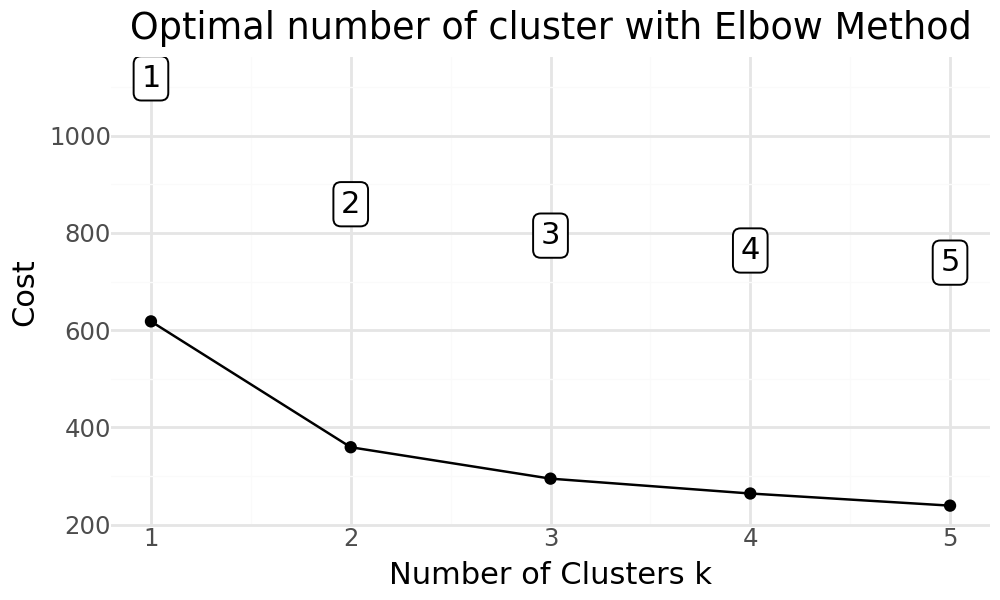

In [108]:
from plotnine import *
import plotnine

plotnine.options.figure_size = (5, 3)
(
    ggplot(data = df_cost)+
    geom_line(aes(x = 'Cluster',
                  y = 'Cost'))+
    geom_point(aes(x = 'Cluster',
                   y = 'Cost'))+
    geom_label(aes(x = 'Cluster',
                   y = 'Cost',
                   label = 'Cluster'),
               size = 11,
               nudge_y = 500) +
    labs(title = 'Optimal number of cluster with Elbow Method')+
    #xlim(0, 11.5) +
    #ylim(230, 500) +
    xlab('Number of Clusters k')+
    ylab('Cost')+
    theme_minimal()
) # Grafico de costos

In [109]:
# optimal K using Elbow method
cost = []
for cluster in range(1, 6):
    try:
        kprototype = KPrototypes(n_clusters = cluster, max_iter= 209, n_init= 35, random_state = 2022, init = 'random', n_jobs = -1)
        kprototype.fit_predict(Xmatrix, categorical = catColumnsPos)
        cost.append(kprototype.cost_)
        print('Cluster initiation: {}'.format(cluster))
    except:
        break

Cluster initiation: 1
Cluster initiation: 2
Cluster initiation: 3
Cluster initiation: 4
Cluster initiation: 5


In [110]:
# results
df_cost = pd.DataFrame({'Cluster':range(1, 6), 'Cost':cost})
df_cost

,Cluster,Cost
0,1,618.133986
1,2,359.180812
2,3,294.558525
3,4,263.973553
4,5,239.012045


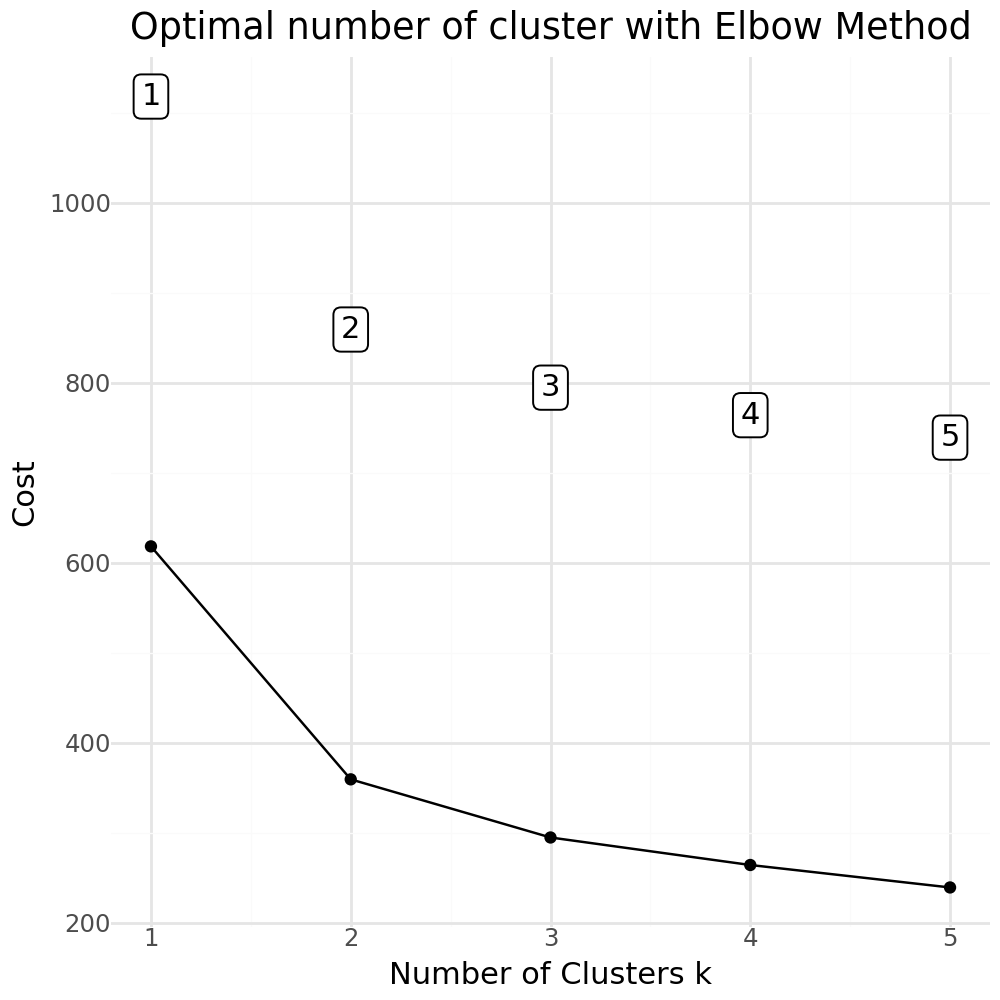

In [111]:
from plotnine import *
import plotnine

plotnine.options.figure_size = (5, 5)
(
    ggplot(data = df_cost)+
    geom_line(aes(x = 'Cluster',
                  y = 'Cost'))+
    geom_point(aes(x = 'Cluster',
                   y = 'Cost'))+
    geom_label(aes(x = 'Cluster',
                   y = 'Cost',
                   label = 'Cluster'),
               size = 11,
               nudge_y = 500) +
    labs(title = 'Optimal number of cluster with Elbow Method')+
    #xlim(0, 11.5) +
    #ylim(230, 500) +
    xlab('Number of Clusters k')+
    ylab('Cost')+
    theme_minimal()
)

## **Gráfico de Silueta: tiene variables numericas y categoricas**

In [112]:
pip install gower

In [113]:
cat_cols = list(x_scaled2.select_dtypes(['object', 'string', 'category']).columns)
num_cols = list(x_scaled2.select_dtypes(['float64', 'int64']).columns)

In [114]:
X = x_scaled2[num_cols + cat_cols].copy() # La matriz va a tener de ambas

for col in cat_cols:
    X[col] = X[col].astype(str)

In [115]:
import gower
# Para las variables numéricas: Calcula la diferencia absoluta normalizada por el rango de la variable.
# Para las variables categóricas: Evalúa si las etiquetas son idénticas o no (0 si coinciden, 1 si son distintas).
D = gower.gower_matrix(X) # Ingresa la matriz completa, entre numerica y numerica se hace un calculo
D

array([[0.        , 0.29152524, 0.33709052, ..., 0.33707294, 0.30660707,
        0.50821966],
       [0.29152524, 0.        , 0.23916495, ..., 0.3703087 , 0.26099664,
        0.48558563],
       [0.33709052, 0.23916495, 0.        , ..., 0.20798694, 0.14626116,
        0.30931842],
       ...,
       [0.33707294, 0.3703087 , 0.20798694, ..., 0.        , 0.19863498,
        0.3092307 ],
       [0.30660707, 0.26099664, 0.14626116, ..., 0.19863498, 0.        ,
        0.38429973],
       [0.50821966, 0.48558563, 0.30931842, ..., 0.3092307 , 0.38429973,
        0.        ]], dtype=float32)

In [116]:
silhouette_scores = []
costs = []

for k in range(2, 6):

    kp = KPrototypes(
        n_clusters=k,
        init='Cao',
        n_init=5,
        random_state=2022
    )

    clusters = kp.fit_predict(
        X.to_numpy(),
        categorical=catColumnsPos
    )

    silhouette = silhouette_score(
        D,
        clusters,
        metric='precomputed'
    )

    silhouette_scores.append(silhouette)
    costs.append(kp.cost_)

    print(
        f"k={k} | "
        f"cost={kp.cost_:.2f} | "
        f"silhouette={silhouette:.4f}"
    )
# Costo (se busca el valor mas pequeño) no puede ser comparado con silueta (se busca el mas grande)

k=2 | cost=359.18 | silhouette=0.3108
k=3 | cost=294.56 | silhouette=0.2124
k=4 | cost=264.99 | silhouette=0.1901
k=5 | cost=239.01 | silhouette=0.1739


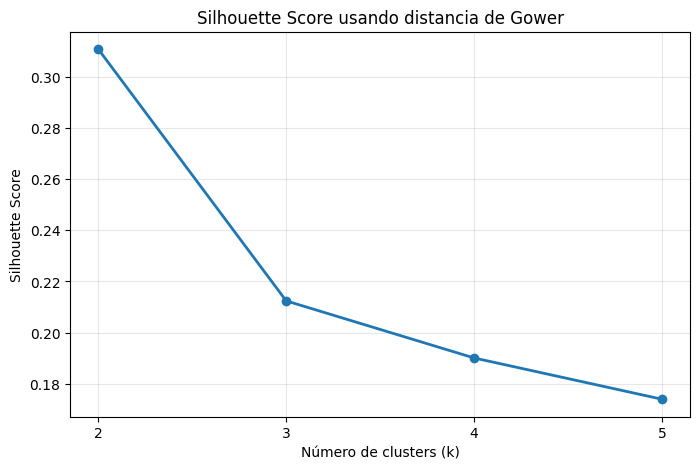

In [117]:
k_values = range(2, 6)

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    silhouette_scores,
    marker='o',
    linewidth=2
)

plt.xlabel('Número de clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score usando distancia de Gower')
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.show()


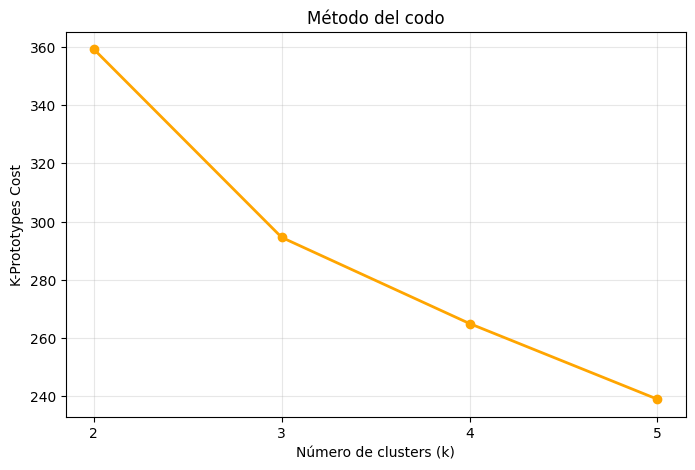

In [118]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    costs,
    marker='o',
    color='orange',
    linewidth=2
)

plt.xlabel('Número de clusters (k)')
plt.ylabel('K-Prototypes Cost')
plt.title('Método del codo')
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.show()


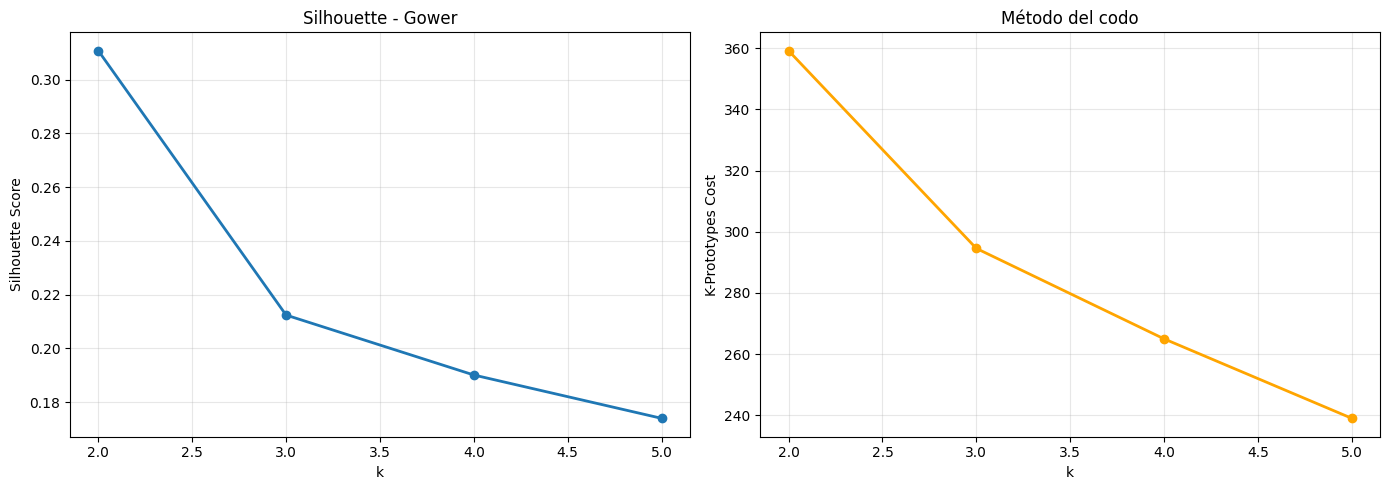

In [119]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Silhouette
ax[0].plot(
    k_values,
    silhouette_scores,
    marker='o',
    linewidth=2
)

ax[0].set_xlabel('k')
ax[0].set_ylabel('Silhouette Score')
ax[0].set_title('Silhouette - Gower')
ax[0].grid(alpha=0.3)

# Cost
ax[1].plot(
    k_values,
    costs,
    marker='o',
    color='orange',
    linewidth=2
)

ax[1].set_xlabel('k')
ax[1].set_ylabel('K-Prototypes Cost')
ax[1].set_title('Método del codo')
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## **Entrenamos el Modelo 2: "KPrototypes"** (con el K óptimo)

Grid para búsqueda de parámetros óptimos

In [120]:
param_grid = {
    #'n_clusters': [2, 3, 4], # Esta comentado porque en la siguiente celda hemos mdefinido 3 clusters
    'max_iter': [100, 200],
    'n_init': [10, 25],
    'init': ['Cao', 'Huang', 'random'],
    'gamma': [0.5, 1, 2]
}

In [121]:
from tqdm.auto import tqdm
import time

resultados = []

total = (
    len(param_grid['max_iter'])
    * len(param_grid['n_init'])
    * len(param_grid['init'])
    * len(param_grid['gamma'])
)

with tqdm(
    total=total,
    desc="K-Prototypes",
    unit="modelo"
) as pbar:

    for max_iter in param_grid['max_iter']:
        for n_init in param_grid['n_init']:
            for init in param_grid['init']:
                for gamma in param_grid['gamma']:

                    pbar.set_postfix(
                        max_iter=max_iter,
                        n_init=n_init,
                        init=init,
                        gamma=gamma
                    )

                    modelo = KPrototypes(
                        n_clusters=3, # 3 clusters
                        max_iter=max_iter,
                        n_init=n_init,
                        gamma=gamma,
                        init=init,
                        random_state=2022,
                        n_jobs=-1
                    )

                    clusters = modelo.fit_predict(
                        Xmatrix,
                        categorical=catColumnsPos
                    )

                    silhouette = silhouette_score(
                        D,
                        clusters,
                        metric='precomputed'
                    )

                    resultados.append({
                        'max_iter': max_iter,
                        'n_init': n_init,
                        'init': init,
                        'gamma': gamma,
                        'cost': modelo.cost_,
                        'silhouette': silhouette
                    })

                    pbar.update(1)


K-Prototypes:   0%|          | 0/36 [00:00<?, ?modelo/s]

In [122]:
resultados_df = pd.DataFrame(resultados)

resultados_df.sort_values(
    'silhouette',
    ascending=False
).head(10)
# gama es el peso que le vamos a dar a las variables categoricas respecto a las numericas

,max_iter,n_init,init,gamma,cost,silhouette
1,100,10,Cao,1.0,654.602362,0.365839
10,100,25,Cao,1.0,654.602362,0.365839
7,100,10,random,1.0,654.602362,0.365839
4,100,10,Huang,1.0,654.602362,0.365839
28,200,25,Cao,1.0,654.602362,0.365839
31,200,25,Huang,1.0,654.602362,0.365839
34,200,25,random,1.0,654.602362,0.365839
13,100,25,Huang,1.0,654.602362,0.365839
16,100,25,random,1.0,654.602362,0.365839
19,200,10,Cao,1.0,654.602362,0.365839


In [123]:
for gamma in [0.1, 0.5, 1, 2, 5, 10]: # Probamos variaciones de gama

    modelo = KPrototypes( # Mantenemos las mejores conbinaciones de la tabla anterior
        n_clusters=3,
        max_iter=200,
        n_init=10,
        gamma=gamma,
        init='Cao',
        random_state=2022,
        n_jobs=-1
    )

    clusters = modelo.fit_predict(
        Xmatrix,
        categorical=catColumnsPos
    )

    clusters = modelo.fit_predict(
                        Xmatrix,
                        categorical=catColumnsPos
                    )

    silhouette = silhouette_score(
        D,
        clusters,
        metric='precomputed'
    )

    print(
        f"gamma={gamma:>4} | "
        f"cost={modelo.cost_:10.4f} | "
        f"silhouette={silhouette:.4f} | "
        f"clusters={np.unique(clusters)}"
    )


gamma= 0.1 | cost=  307.8334 | silhouette=0.2145 | clusters=[0 1 2]
gamma= 0.5 | cost=  503.0421 | silhouette=0.3621 | clusters=[0 1 2]
gamma=   1 | cost=  654.6024 | silhouette=0.3658 | clusters=[0 1 2]
gamma=   2 | cost=  943.8349 | silhouette=0.3657 | clusters=[0 1 2]
gamma=   5 | cost= 1810.8349 | silhouette=0.3657 | clusters=[0 1 2]
gamma=  10 | cost= 3255.8349 | silhouette=0.3657 | clusters=[0 1 2]


Construimos el Modelo

In [124]:
modelo2 = KPrototypes(n_clusters = 3, max_iter= 100, n_init= 10, random_state = 2022, init = 'Cao', gamma = 1, n_jobs = -1)
modelo2.fit_predict(Xmatrix, categorical = catColumnsPos)

array([2, 0, 0, ..., 2, 0, 1], dtype=uint16)

Cluster centroids

In [125]:
modelo2.cluster_centroids_

array([[0.47985760611481487, 0.7232094862142123, 0.2394586827421995,
        0.1430165120739296, 0.5395324578362655, 0.17799386248976676,
        0.11836215793366689, 0.3339977851605759,
        Interval(0.134, 0.151, closed='right')],
       [0.6700199670645197, 0.8512490759912235, 0.3754023495000824,
        0.14091518064844127, 0.6612896576442509, 0.20130648527552955,
        0.11385705773850684, 0.35038961038961064,
        Interval(0.151, 0.168, closed='right')],
       [0.29171832331814784, 0.4225576392477764, 0.11448435658760388,
        0.24017975207690523, 0.17384925140748225, 0.10956799400437037,
        0.10406157698007333, 0.41806797853309624,
        Interval(0.117, 0.134, closed='right')]], dtype=object)

In [126]:
# cost of the clusters created
modelo2.cost_

np.float64(654.6023618331501)

In [127]:
x['Cluster_modelo2'] = modelo2.labels_
x['Cluster_modelo2']

,Cluster_modelo2
s010101_CHACHAPOYAS,2
s010102_ASUNCION,0
s010103_BALSAS,0
s010104_CHETO,0
s010105_CHILIQUIN,1
...,...
s250302_IRAZOLA,0
s250303_CURIMANA,0
s250304_NESHUYA,2
s250305_ALEXANDER VON HUMBOLDT,0


Casos por Cluster

In [128]:
x['Cluster_modelo2'].value_counts()

,count
Cluster_modelo2,
0,903
2,559
1,385


In [129]:
x.columns #etiquetas

Index(['NOTIENEAGUA', 'NOTIENEDESAGUE', 'NOTIENEELECTRICIDAD', 'NOTIENESEGURO',
       'RURAL', 'ANALFABETISMO', 'CONDISCAPACIDAD', 'PROMEDIODEHOGARES',
       'SINEQUIPOSDECOMUNICACION', 'Cluster_modelo1', 'Cluster_modelo3',
       'Cluster_modelo2'],
      dtype='object')

In [130]:
x['Cluster_modelo2']

,Cluster_modelo2
s010101_CHACHAPOYAS,2
s010102_ASUNCION,0
s010103_BALSAS,0
s010104_CHETO,0
s010105_CHILIQUIN,1
...,...
s250302_IRAZOLA,0
s250303_CURIMANA,0
s250304_NESHUYA,2
s250305_ALEXANDER VON HUMBOLDT,0


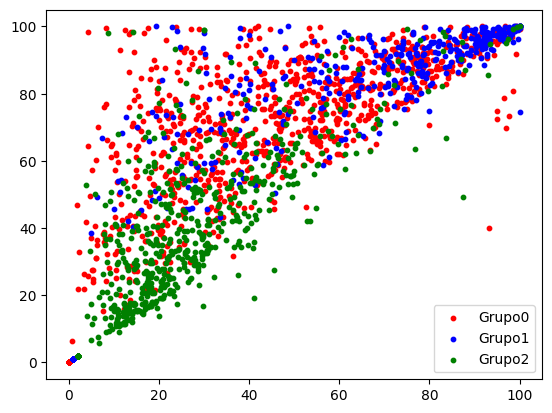

In [131]:
plt.scatter(x[x.Cluster_modelo2 == 0][['Cluster_modelo2', 'NOTIENEAGUA']], x[x.Cluster_modelo2 == 0][['Cluster_modelo2', 'NOTIENEDESAGUE']], s = 10, c = 'red', label = 'Grupo0')
plt.scatter(x[x.Cluster_modelo2 == 1][['Cluster_modelo2', 'NOTIENEAGUA']], x[x.Cluster_modelo2 == 1][['Cluster_modelo2', 'NOTIENEDESAGUE']], s = 10, c = 'blue', label = 'Grupo1')
plt.scatter(x[x.Cluster_modelo2 == 2][['Cluster_modelo2', 'NOTIENEAGUA']], x[x.Cluster_modelo2 == 2][['Cluster_modelo2', 'NOTIENEDESAGUE']], s = 10, c = 'green', label = 'Grupo2')
plt.legend()

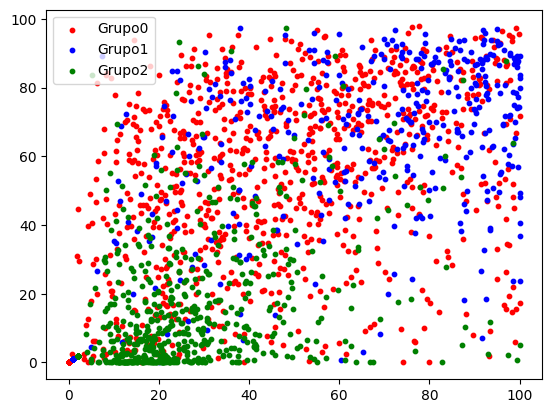

In [132]:
plt.scatter(x[x.Cluster_modelo2 == 0][['Cluster_modelo2', 'NOTIENEAGUA']], x[x.Cluster_modelo2 == 0][['Cluster_modelo2', 'RURAL']], s = 10, c = 'red', label = 'Grupo0')
plt.scatter(x[x.Cluster_modelo2 == 1][['Cluster_modelo2', 'NOTIENEAGUA']], x[x.Cluster_modelo2 == 1][['Cluster_modelo2', 'RURAL']], s = 10, c = 'blue', label = 'Grupo1')
plt.scatter(x[x.Cluster_modelo2 == 2][['Cluster_modelo2', 'NOTIENEAGUA']], x[x.Cluster_modelo2 == 2][['Cluster_modelo2', 'RURAL']], s = 10, c = 'green', label = 'Grupo2')
plt.legend() # El k-mean o jerarquico son mejores

In [133]:
import plotly.express as px
from sklearn.decomposition import PCA

datos_pca_plot = x.copy()
#datos_pca_plot['Cluster_modelo2'] = datos['Cluster_modelo2']

fig = px.scatter_3d( datos_pca_plot, x='NOTIENEAGUA', y='RURAL', z='NOTIENEDESAGUE', color='Cluster_modelo2'
)
fig.show() # El k-mean o jerarquico son mejores

In [134]:
# Descriptivos del Cluster 0
x[x.Cluster_modelo2 == 0].describe()

,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,SINEQUIPOSDECOMUNICACION,Cluster_modelo1,Cluster_modelo3,Cluster_modelo2
count,903.000000,903.000000,903.000000,903.000000,903.000000,903.000000,903.000000,903.000000,903.000000,903.000000,903.000000,903.0
mean,47.985761,72.320949,23.945868,14.301651,53.953246,17.799386,11.836216,2.669989,14.291373,0.838317,2.277962,0.0
std,25.507681,19.507979,12.622731,9.223224,25.867380,5.382648,5.033774,0.615448,0.564485,0.897394,0.790206,0.0
min,0.645161,6.451613,1.923077,1.616304,0.000000,3.426791,1.969058,1.000000,8.098548,0.000000,1.000000,0.0
25%,26.476954,60.919226,15.128507,7.370828,35.535598,14.218362,8.239377,2.000000,13.914639,0.000000,2.000000,0.0
50%,45.823719,75.312344,21.472393,11.662107,57.794274,17.622951,10.650282,3.000000,14.331540,1.000000,2.000000,0.0
75%,67.177227,87.984517,30.221565,19.832109,74.879049,21.481481,14.513762,3.000000,14.654126,2.000000,3.000000,0.0
max,100.000000,100.000000,76.228686,58.083702,97.798239,37.574850,33.219178,5.000000,18.413866,2.000000,3.000000,0.0


In [135]:
# Descriptivos del Cluster 1
x[x.Cluster_modelo2 == 1].describe()

,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,SINEQUIPOSDECOMUNICACION,Cluster_modelo1,Cluster_modelo3,Cluster_modelo2
count,385.000000,385.000000,385.000000,385.000000,385.000000,385.000000,385.000000,385.000000,385.000000,385.000000,385.000000,385.0
mean,67.001997,85.124908,37.540235,14.091518,66.128966,20.130649,11.385706,2.751948,15.881022,1.407792,1.703896,1.0
std,25.721748,14.645663,19.722354,10.261364,21.793609,5.918876,6.015552,0.883237,0.702023,0.885321,0.851231,0.0
min,4.868914,38.576779,4.494382,1.063830,0.000000,4.302926,1.688404,1.000000,12.569593,0.000000,1.000000,1.0
25%,46.884273,78.461538,22.594142,6.695812,53.598798,16.298553,6.777646,2.000000,15.367803,0.000000,1.000000,1.0
50%,73.834832,90.159574,33.593750,10.875706,70.461155,20.226044,10.380117,3.000000,15.718985,2.000000,1.000000,1.0
75%,89.892802,96.532334,46.842105,19.215503,83.637417,24.010791,14.898420,3.000000,16.214233,2.000000,3.000000,1.0
max,100.000000,100.000000,100.000000,63.675958,97.212476,40.579022,51.960784,6.000000,18.502964,2.000000,3.000000,1.0


In [136]:
# Descriptivos del Cluster 2
x[x.Cluster_modelo2 == 2].describe()

,NOTIENEAGUA,NOTIENEDESAGUE,NOTIENEELECTRICIDAD,NOTIENESEGURO,RURAL,ANALFABETISMO,CONDISCAPACIDAD,PROMEDIODEHOGARES,SINEQUIPOSDECOMUNICACION,Cluster_modelo1,Cluster_modelo3,Cluster_modelo2
count,559.000000,559.000000,559.000000,559.000000,559.000000,559.000000,559.000000,559.000000,559.000000,559.000000,559.000000,559.0
mean,29.171832,42.255764,11.448436,24.017975,17.384925,10.956799,10.406158,3.090340,11.363630,0.876565,2.908766,2.0
std,18.465887,22.038109,7.814585,9.237872,20.115592,3.597296,2.930068,0.558717,2.268348,0.444970,0.349980,0.0
min,3.875969,5.680586,0.000000,3.152455,0.000000,1.770492,1.640958,1.000000,1.473746,0.000000,1.000000,2.0
25%,16.428686,24.426084,6.162824,17.660168,1.963581,8.588574,8.893461,3.000000,10.466017,1.000000,3.000000,2.0
50%,24.056528,38.449283,10.180447,23.927857,9.847292,10.553927,10.235849,3.000000,12.039558,1.000000,3.000000,2.0
75%,37.655787,56.475148,15.307782,29.833147,26.480794,12.937710,11.709700,3.000000,12.917343,1.000000,3.000000,2.0
max,100.000000,100.000000,53.165468,66.555688,97.308828,33.115672,34.221311,4.000000,17.108813,2.000000,3.000000,2.0


# **Contraste de Modelos**

In [137]:
x[['Cluster_modelo1','Cluster_modelo2','Cluster_modelo3']].head(10)

,Cluster_modelo1,Cluster_modelo2,Cluster_modelo3
s010101_CHACHAPOYAS,1,2,3
s010102_ASUNCION,1,0,3
s010103_BALSAS,0,0,2
s010104_CHETO,1,0,3
s010105_CHILIQUIN,2,1,1
s010106_CHUQUIBAMBA,0,0,2
s010107_GRANADA,2,0,1
s010108_HUANCAS,1,0,3
s010109_LA JALCA,0,0,3
s010110_LEIMEBAMBA,1,0,3


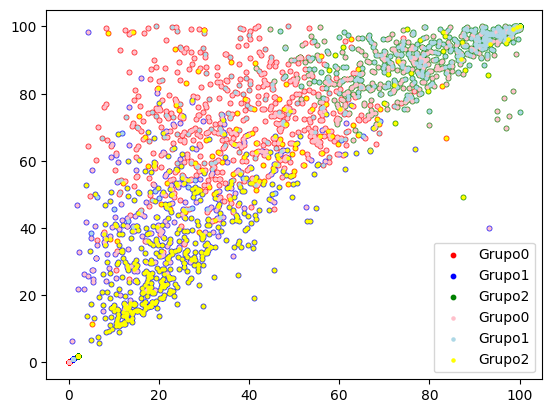

In [138]:
#Modelo1
plt.scatter(x[x.Cluster_modelo1 == 0][['Cluster_modelo1', 'NOTIENEAGUA']], x[x.Cluster_modelo1 == 0][['Cluster_modelo1', 'NOTIENEDESAGUE']], s = 10, c = 'red', label = 'Grupo0')
plt.scatter(x[x.Cluster_modelo1 == 1][['Cluster_modelo1', 'NOTIENEAGUA']], x[x.Cluster_modelo1 == 1][['Cluster_modelo1', 'NOTIENEDESAGUE']], s = 10, c = 'blue', label = 'Grupo1')
plt.scatter(x[x.Cluster_modelo1 == 2][['Cluster_modelo1', 'NOTIENEAGUA']], x[x.Cluster_modelo1 == 2][['Cluster_modelo1', 'NOTIENEDESAGUE']], s = 10, c = 'green', label = 'Grupo2')

#Modelo2
plt.scatter(x[x.Cluster_modelo2 == 0][['Cluster_modelo2', 'NOTIENEAGUA']], x[x.Cluster_modelo2 == 0][['Cluster_modelo2', 'NOTIENEDESAGUE']], s = 5, c = 'pink', label = 'Grupo0')
plt.scatter(x[x.Cluster_modelo2 == 1][['Cluster_modelo2', 'NOTIENEAGUA']], x[x.Cluster_modelo2 == 1][['Cluster_modelo2', 'NOTIENEDESAGUE']], s = 5, c = 'lightblue', label = 'Grupo1')
plt.scatter(x[x.Cluster_modelo2 == 2][['Cluster_modelo2', 'NOTIENEAGUA']], x[x.Cluster_modelo2 == 2][['Cluster_modelo2', 'NOTIENEDESAGUE']], s = 5, c = 'yellow', label = 'Grupo2')

plt.legend()

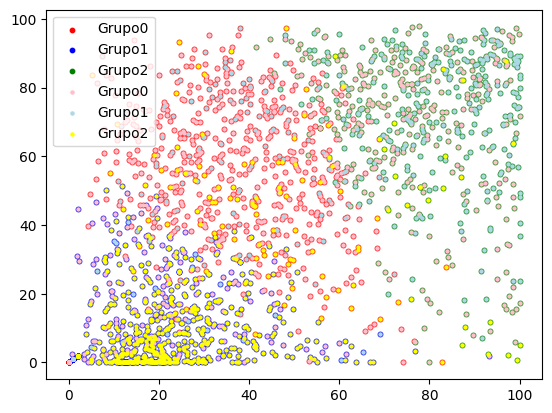

In [139]:
# Modelo1
plt.scatter(x[x.Cluster_modelo1 == 0][['Cluster_modelo1', 'NOTIENEAGUA']], x[x.Cluster_modelo1 == 0][['Cluster_modelo1', 'RURAL']], s = 10, c = 'red', label = 'Grupo0')
plt.scatter(x[x.Cluster_modelo1 == 1][['Cluster_modelo1', 'NOTIENEAGUA']], x[x.Cluster_modelo1 == 1][['Cluster_modelo1', 'RURAL']], s = 10, c = 'blue', label = 'Grupo1')
plt.scatter(x[x.Cluster_modelo1 == 2][['Cluster_modelo1', 'NOTIENEAGUA']], x[x.Cluster_modelo1 == 2][['Cluster_modelo1', 'RURAL']], s = 10, c = 'green', label = 'Grupo2')

#Modelo2
plt.scatter(x[x.Cluster_modelo2 == 0][['Cluster_modelo2', 'NOTIENEAGUA']], x[x.Cluster_modelo2 == 0][['Cluster_modelo2', 'RURAL']], s = 5, c = 'pink', label = 'Grupo0')
plt.scatter(x[x.Cluster_modelo2 == 1][['Cluster_modelo2', 'NOTIENEAGUA']], x[x.Cluster_modelo2 == 1][['Cluster_modelo2', 'RURAL']], s = 5, c = 'lightblue', label = 'Grupo1')
plt.scatter(x[x.Cluster_modelo2 == 2][['Cluster_modelo2', 'NOTIENEAGUA']], x[x.Cluster_modelo2 == 2][['Cluster_modelo2', 'RURAL']], s = 5, c = 'yellow', label = 'Grupo2')

plt.legend()

# **Comparando Silhouette**

In [140]:
from sklearn.metrics import silhouette_score

sil_kmeans = silhouette_score(
    D,
    x.Cluster_modelo1,
    metric='precomputed'
)

sil_kproto = silhouette_score(
    D,
    x.Cluster_modelo2,
    metric='precomputed'
)

sil_hierarchical = silhouette_score(
    D,
    x.Cluster_modelo3,
    metric='precomputed'
)

print("K-Means:", sil_kmeans)
print("K-Prototypes:", sil_kproto)
print("Jerárquico:", sil_hierarchical)


K-Means: 0.19606403
K-Prototypes: 0.36583877
Jerárquico: 0.113461666


Comparaciones de Silhouette, con la misma D, sirve para:

Comparar la calidad de las particiones bajo una misma definición de similitud.

# **Comparando Estabilidad**

In [141]:
seeds = [1, 10, 42, 100, 2022]
k = 3

KMeans

In [142]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

resultados_kmeans = []

labels_kmeans = {}

for seed in seeds:

    modelo = KMeans(
        n_clusters=k,
        n_init=20,
        random_state=seed
    )

    labels = modelo.fit_predict(
        x_scaled2.select_dtypes(include="float64")
    )

    labels_kmeans[seed] = labels

    # Silhouette usando Gower
    silhouette = silhouette_score(
        D,
        labels,
        metric='precomputed'
    )

    resultados_kmeans.append({
        'seed': seed,
        'silhouette_gower': silhouette,
        'inertia': modelo.inertia_
    })

resultados_kmeans = pd.DataFrame(resultados_kmeans)

resultados_kmeans


,seed,silhouette_gower,inertia
0,1,0.196064,221.715611
1,10,0.196064,221.715611
2,42,0.195767,221.716158
3,100,0.195767,221.716158
4,2022,0.196064,221.715611


**silhouette_gower**: ¿Qué tan bien separados y cohesionados están mis clusters según Gower? El valor está aproximadamente entre: -1 y 1.

**inertia**: ¿Qué tan cerca están las observaciones de los prototipos según la función de costo de K-Prototypes?

**ARI**: ¿Cuánto cambia la asignación de clusters cuando vuelvo a ejecutar el algoritmo con otra semilla?

In [143]:
import itertools
import numpy as np

ari_kmeans = []

for seed1, seed2 in itertools.combinations(seeds, 2):

    ari = adjusted_rand_score(
        labels_kmeans[seed1],
        labels_kmeans[seed2]
    )

    ari_kmeans.append({
        'seed_1': seed1,
        'seed_2': seed2,
        'ARI': ari
    })

ari_kmeans = pd.DataFrame(ari_kmeans)

ari_kmeans


,seed_1,seed_2,ARI
0,1,10,1.000000
1,1,42,0.995091
2,1,100,0.995091
3,1,2022,1.000000
4,10,42,0.995091
5,10,100,0.995091
6,10,2022,1.000000
7,42,100,1.000000
8,42,2022,0.995091
9,100,2022,0.995091


KPrototypes

In [144]:
resultados_kproto = []

labels_kproto = {}

for seed in seeds:

    modelo = KPrototypes(
        n_clusters=k,
        max_iter=200,
        n_init=20,
        init='Cao',
        gamma=1,
        random_state=seed,
        n_jobs=-1
    )

    labels = modelo.fit_predict(
        Xmatrix,
        categorical=catColumnsPos
    )

    labels_kproto[seed] = labels

    # Silhouette con Gower
    silhouette = silhouette_score(
        D,
        labels,
        metric='precomputed'
    )

    resultados_kproto.append({
        'seed': seed,
        'silhouette_gower': silhouette,
        'cost': modelo.cost_
    })

resultados_kproto = pd.DataFrame(resultados_kproto)

resultados_kproto


,seed,silhouette_gower,cost
0,1,0.365839,654.602362
1,10,0.365839,654.602362
2,42,0.365839,654.602362
3,100,0.365839,654.602362
4,2022,0.365839,654.602362


In [145]:
ari_kproto = []

for seed1, seed2 in itertools.combinations(seeds, 2):

    ari = adjusted_rand_score(
        labels_kproto[seed1],
        labels_kproto[seed2]
    )

    ari_kproto.append({
        'seed_1': seed1,
        'seed_2': seed2,
        'ARI': ari
    })

ari_kproto = pd.DataFrame(ari_kproto)

ari_kproto


,seed_1,seed_2,ARI
0,1,10,1.0
1,1,42,1.0
2,1,100,1.0
3,1,2022,1.0
4,10,42,1.0
5,10,100,1.0
6,10,2022,1.0
7,42,100,1.0
8,42,2022,1.0
9,100,2022,1.0


AGNES

In [146]:
resultados_jerarquico = []

labels_jerarquico = {}

# Convertimos la matriz de Gower a formato condensado
D_condensed = squareform(D)

# Construimos el dendrograma
Z = linkage(
    D_condensed,
    method='average'
)

# Cortamos el dendrograma en k clusters
labels = fcluster(
    Z,
    t=k,
    criterion='maxclust'
)

labels_jerarquico[k] = labels

# Silhouette con Gower
silhouette = silhouette_score(
    D,
    labels,
    metric='precomputed'
)

resultados_jerarquico.append({
    'k': k,
    'silhouette_gower': silhouette
})

resultados_jerarquico = pd.DataFrame(resultados_jerarquico)

resultados_jerarquico

,k,silhouette_gower
0,3,0.307576


**Comparación de la estructura de clusters mediante Adjusted Rand Index (ARI)**

In [147]:
from sklearn.metrics import adjusted_rand_score

ari_kmeans_kproto = adjusted_rand_score(
    labels_kmeans[seed1],
    labels_kproto[seed1]
)

ari_kmeans_jerarquico = adjusted_rand_score(
    labels_kmeans[seed1],
    labels_jerarquico[3]
)

ari_kproto_jerarquico = adjusted_rand_score(
    labels_kproto[seed1],
    labels_jerarquico[3]
)

print("K-Means vs K-Prototypes:", ari_kmeans_kproto)
print("K-Means vs Jerárquico:", ari_kmeans_jerarquico)
print("K-Prototypes vs Jerárquico:", ari_kproto_jerarquico)


K-Means vs K-Prototypes: 0.21809057324285977
K-Means vs Jerárquico: 0.2123282691766341
K-Prototypes vs Jerárquico: 0.595532321619114


ARI, labels de cada algoritmo con su propia D, sirve para:

Comparar si los algoritmos están encontrando los mismos grupos.